# Свёрточные сети.

1. Обучение CNN на MNIST
2. Transfer learning на FashionMNIST с разными стратегиями заморозки
3. Сравнение кривых обучения
4. Анализ наиболее путаемых изображений

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
import copy

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

mnist_train = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
mnist_test = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

fmnist_train = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
fmnist_test = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)
чё
batch_size = 128

mnist_train_loader = DataLoader(mnist_train, batch_size=batch_size, shuffle=True)
mnist_test_loader = DataLoader(mnist_test, batch_size=batch_size, shuffle=False)

fmnist_train_loader = DataLoader(fmnist_train, batch_size=batch_size, shuffle=True)
fmnist_test_loader = DataLoader(fmnist_test, batch_size=batch_size, shuffle=False)

print(f"MNIST: train={len(mnist_train)}, test={len(mnist_test)}")
print(f"FashionMNIST: train={len(fmnist_train)}, test={len(fmnist_test)}")

Device: cuda
MNIST: train=60000, test=10000
FashionMNIST: train=60000, test=10000


## 1. Архитектура CNN

Свёрточная сеть с общим «телом» (backbone) и сменными «головами» (heads) для разных задач.

In [3]:
class ConvBackbone(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.conv3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1)
        )

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        return x.view(x.size(0), -1)


class ClassificationHead(nn.Module):
    def __init__(self, in_features=128, num_classes=10):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(in_features, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.fc(x)


class MultiHeadCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = ConvBackbone()
        self.head1 = ClassificationHead(128, 10)
        self.head2 = None

    def forward(self, x, head='head1'):
        features = self.backbone(x)
        if head == 'head1':
            return self.head1(features)
        elif head == 'head2':
            assert self.head2 is not None, "Head2 not initialized"
            return self.head2(features)

    def add_head2(self):
        self.head2 = ClassificationHead(128, 10)
        return self

    def freeze_backbone(self):
        for param in self.backbone.parameters():
            param.requires_grad = False

    def unfreeze_backbone(self):
        for param in self.backbone.parameters():
            param.requires_grad = True

    def freeze_initial_layers(self, n_layers=2):
        layers = [self.backbone.conv1, self.backbone.conv2, self.backbone.conv3]
        for layer in layers[:n_layers]:
            for param in layer.parameters():
                param.requires_grad = False


model = MultiHeadCNN().to(device)
print(model)
total_params = sum(p.numel() for p in model.parameters())
print(f"\nОбщее число параметров: {total_params:,}")

MultiHeadCNN(
  (backbone): ConvBackbone(
    (conv1): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (conv2): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (conv3): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): AdaptiveAvgPool2d(output_size=1)
    )
  )
  (head1): ClassificationHead(
    (fc): Sequential(
      (0): Linear(in_features=128

## 2. Функция обучения и оценки

In [4]:
def evaluate(model, loader, criterion, head='head1'):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images, head=head)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += images.size(0)
    return total_loss / total, correct / total


def train_model(model, train_loader, test_loader, criterion, optimizer,
                epochs=10, head='head1', label=''):
    history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images, head=head)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += images.size(0)

        train_loss = running_loss / total
        train_acc = correct / total
        test_loss, test_acc = evaluate(model, test_loader, criterion, head=head)

        history['train_loss'].append(train_loss)
        history['test_loss'].append(test_loss)
        history['train_acc'].append(train_acc)
        history['test_acc'].append(test_acc)

        print(f"[{label}] Epoch {epoch+1}/{epochs}: "
              f"train_loss={train_loss:.4f}, train_acc={train_acc:.4f}, "
              f"test_loss={test_loss:.4f}, test_acc={test_acc:.4f}")

    return history


def plot_curves(history, title=''):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    epochs = range(1, len(history['train_loss']) + 1)

    ax1.plot(epochs, history['train_loss'], label='Train')
    ax1.plot(epochs, history['test_loss'], label='Test')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.set_title(f'{title} — Loss')
    ax1.legend()
    ax1.grid(True)

    ax2.plot(epochs, history['train_acc'], label='Train')
    ax2.plot(epochs, history['test_acc'], label='Test')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.set_title(f'{title} — Accuracy')
    ax2.legend()
    ax2.grid(True)

    plt.tight_layout()
    plt.show()

all_histories = {}

## 3. Обучение на MNIST

Обучаем всю сеть (backbone + head1) на задаче классификации MNIST. Используем перекрёстную энтропию как функцию потерь.

[MNIST] Epoch 1/10: train_loss=0.5128, train_acc=0.8487, test_loss=0.1307, test_acc=0.9641
[MNIST] Epoch 2/10: train_loss=0.1259, train_acc=0.9656, test_loss=0.4573, test_acc=0.8562
[MNIST] Epoch 3/10: train_loss=0.0908, train_acc=0.9750, test_loss=0.0860, test_acc=0.9756
[MNIST] Epoch 4/10: train_loss=0.0728, train_acc=0.9796, test_loss=0.2029, test_acc=0.9373
[MNIST] Epoch 5/10: train_loss=0.0584, train_acc=0.9833, test_loss=0.0874, test_acc=0.9727
[MNIST] Epoch 6/10: train_loss=0.0547, train_acc=0.9844, test_loss=0.1636, test_acc=0.9498
[MNIST] Epoch 7/10: train_loss=0.0479, train_acc=0.9860, test_loss=0.0993, test_acc=0.9699
[MNIST] Epoch 8/10: train_loss=0.0414, train_acc=0.9876, test_loss=0.1083, test_acc=0.9646
[MNIST] Epoch 9/10: train_loss=0.0375, train_acc=0.9889, test_loss=0.0333, test_acc=0.9899
[MNIST] Epoch 10/10: train_loss=0.0349, train_acc=0.9898, test_loss=0.0478, test_acc=0.9852


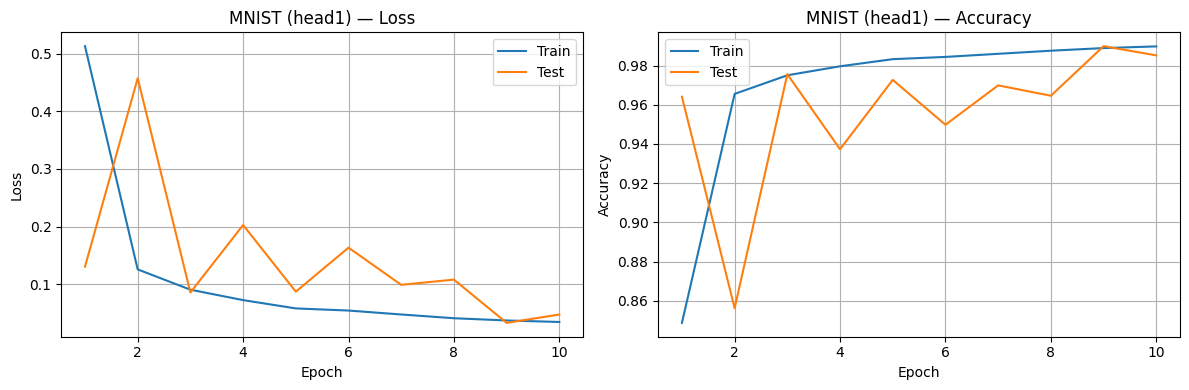

In [5]:
model = MultiHeadCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

history_mnist = train_model(
    model, mnist_train_loader, mnist_test_loader,
    criterion, optimizer, epochs=10, head='head1', label='MNIST'
)
all_histories['MNIST (head1)'] = history_mnist
plot_curves(history_mnist, 'MNIST (head1)')

## 4. head2 и сохранение параметров

Добавляем head2 (для FashionMNIST) и сохраняем все параметры: backbone, head1 (обученная) и head2 (необученная).

In [6]:
model.add_head2()
model.head2 = model.head2.to(device)

saved_state = {
    'backbone': copy.deepcopy(model.backbone.state_dict()),
    'head1': copy.deepcopy(model.head1.state_dict()),
    'head2': copy.deepcopy(model.head2.state_dict()),
}
torch.save(saved_state, 'checkpoint_after_mnist.pth')

## 5. Обучение head2 на FashionMNIST

Замораживаем свёрточные слои и обучаем только вторую голову на FashionMNIST.

[FashionMNIST (frozen backbone)] Epoch 1/10: train_loss=1.2220, train_acc=0.5724, test_loss=0.8515, test_acc=0.7016
[FashionMNIST (frozen backbone)] Epoch 2/10: train_loss=0.8587, train_acc=0.6882, test_loss=0.7222, test_acc=0.7354
[FashionMNIST (frozen backbone)] Epoch 3/10: train_loss=0.7694, train_acc=0.7195, test_loss=0.6693, test_acc=0.7534
[FashionMNIST (frozen backbone)] Epoch 4/10: train_loss=0.7231, train_acc=0.7350, test_loss=0.6363, test_acc=0.7657
[FashionMNIST (frozen backbone)] Epoch 5/10: train_loss=0.6923, train_acc=0.7462, test_loss=0.6232, test_acc=0.7677
[FashionMNIST (frozen backbone)] Epoch 6/10: train_loss=0.6694, train_acc=0.7562, test_loss=0.5919, test_acc=0.7776
[FashionMNIST (frozen backbone)] Epoch 7/10: train_loss=0.6476, train_acc=0.7637, test_loss=0.5809, test_acc=0.7834
[FashionMNIST (frozen backbone)] Epoch 8/10: train_loss=0.6311, train_acc=0.7710, test_loss=0.5666, test_acc=0.7882
[FashionMNIST (frozen backbone)] Epoch 9/10: train_loss=0.6192, train_ac

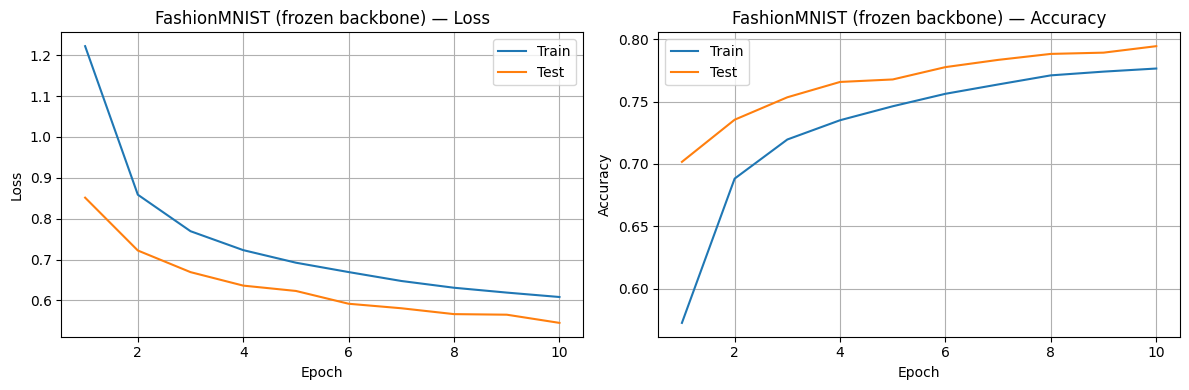

In [7]:
model.freeze_backbone()

optimizer_head2 = optim.Adam(model.head2.parameters(), lr=1e-3)

history_fmnist_frozen = train_model(
    model, fmnist_train_loader, fmnist_test_loader,
    criterion, optimizer_head2, epochs=10, head='head2',
    label='FashionMNIST (frozen backbone)'
)
all_histories['FashionMNIST (frozen backbone)'] = history_fmnist_frozen
plot_curves(history_fmnist_frozen, 'FashionMNIST (frozen backbone)')

## 6. Разморозка backbone и дообучение head2

Размораживаем свёрточные слои и дообучаем всю сеть для FashionMNIST. Строим кривые для обеих задач.

[FashionMNIST] Epoch 1/10: train_loss=0.5320, train_acc=0.8097, test_loss=0.4539, test_acc=0.8312
[FashionMNIST] Epoch 2/10: train_loss=0.4704, train_acc=0.8336, test_loss=0.4138, test_acc=0.8502
[FashionMNIST] Epoch 3/10: train_loss=0.4334, train_acc=0.8480, test_loss=0.3899, test_acc=0.8612
[FashionMNIST] Epoch 4/10: train_loss=0.4070, train_acc=0.8577, test_loss=0.3716, test_acc=0.8656
[FashionMNIST] Epoch 5/10: train_loss=0.3854, train_acc=0.8659, test_loss=0.3612, test_acc=0.8681
[FashionMNIST] Epoch 6/10: train_loss=0.3739, train_acc=0.8706, test_loss=0.3460, test_acc=0.8778
[FashionMNIST] Epoch 7/10: train_loss=0.3583, train_acc=0.8749, test_loss=0.3372, test_acc=0.8811
[FashionMNIST] Epoch 8/10: train_loss=0.3470, train_acc=0.8793, test_loss=0.3272, test_acc=0.8845
[FashionMNIST] Epoch 9/10: train_loss=0.3385, train_acc=0.8821, test_loss=0.3240, test_acc=0.8843
[FashionMNIST] Epoch 10/10: train_loss=0.3269, train_acc=0.8854, test_loss=0.3161, test_acc=0.8874


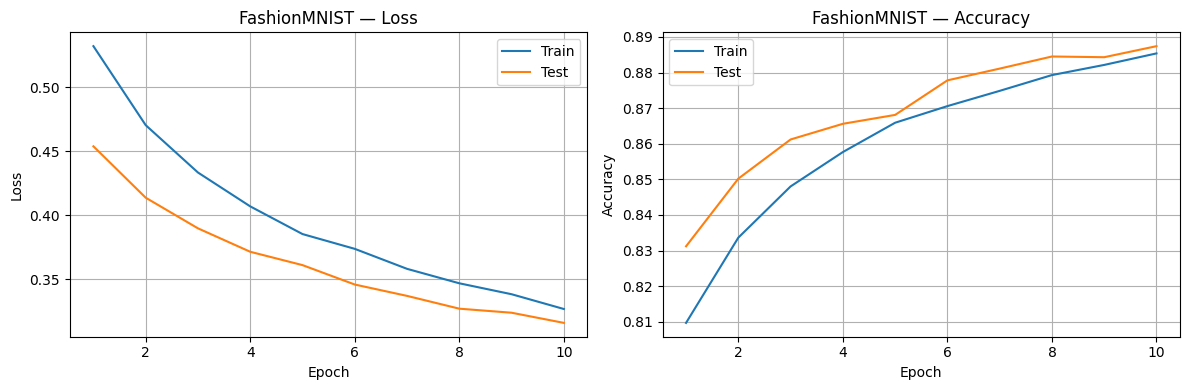


MNIST (head1) после дообучения backbone: loss=3.5278, acc=0.4272


In [8]:
model.unfreeze_backbone()

optimizer_finetune = optim.Adam(model.parameters(), lr=1e-4)

history_fmnist_unfrozen = train_model(
    model, fmnist_train_loader, fmnist_test_loader,
    criterion, optimizer_finetune, epochs=10, head='head2',
    label='FashionMNIST'
)
all_histories['FashionMNIST (unfreeze finetune)'] = history_fmnist_unfrozen
plot_curves(history_fmnist_unfrozen, 'FashionMNIST')

mnist_loss_after, mnist_acc_after = evaluate(model, mnist_test_loader, criterion, head='head1')
print(f"\nMNIST (head1) после дообучения backbone: loss={mnist_loss_after:.4f}, acc={mnist_acc_after:.4f}")

## 7. Загрузка сохранённых параметров и обучение head2 (backbone разморожен)

Загружаем сохранённые ранее параметры (backbone обучен на MNIST, head2 случайная). Обучаем head2 сразу с разморожёнными свёрточными слоями.

[FashionMNIST] Epoch 1/10: train_loss=1.5208, train_acc=0.5137, test_loss=0.9303, test_acc=0.7272
[FashionMNIST] Epoch 2/10: train_loss=0.8164, train_acc=0.7200, test_loss=0.6338, test_acc=0.7723
[FashionMNIST] Epoch 3/10: train_loss=0.6355, train_acc=0.7710, test_loss=0.5334, test_acc=0.8037
[FashionMNIST] Epoch 4/10: train_loss=0.5488, train_acc=0.8025, test_loss=0.4766, test_acc=0.8281
[FashionMNIST] Epoch 5/10: train_loss=0.4908, train_acc=0.8242, test_loss=0.4385, test_acc=0.8435
[FashionMNIST] Epoch 6/10: train_loss=0.4544, train_acc=0.8398, test_loss=0.4088, test_acc=0.8554
[FashionMNIST] Epoch 7/10: train_loss=0.4252, train_acc=0.8507, test_loss=0.3896, test_acc=0.8643
[FashionMNIST] Epoch 8/10: train_loss=0.4054, train_acc=0.8581, test_loss=0.3791, test_acc=0.8690
[FashionMNIST] Epoch 9/10: train_loss=0.3865, train_acc=0.8651, test_loss=0.3652, test_acc=0.8728
[FashionMNIST] Epoch 10/10: train_loss=0.3733, train_acc=0.8686, test_loss=0.3619, test_acc=0.8737


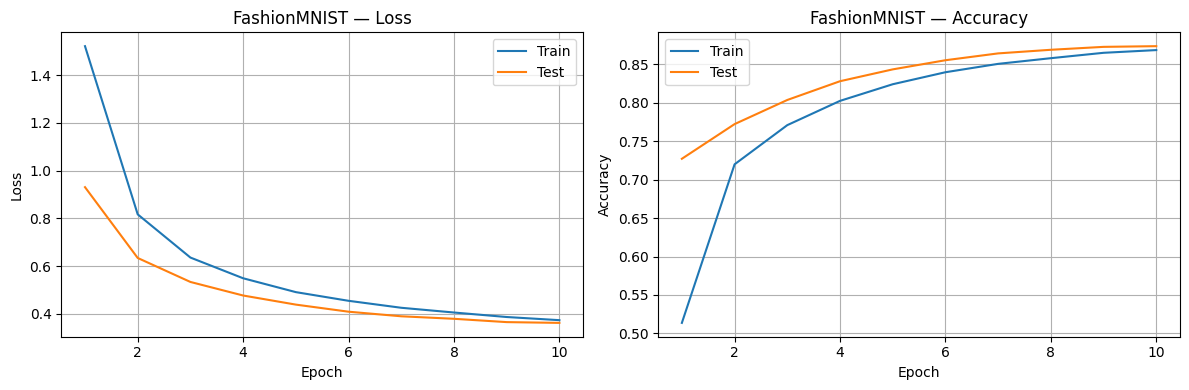


MNIST (head1) после обучения с разморозкой: loss=5.4022, acc=0.3290


In [9]:
model2 = MultiHeadCNN().to(device)
model2.add_head2()
model2.head2 = model2.head2.to(device)

checkpoint = torch.load('checkpoint_after_mnist.pth', weights_only=True)
model2.backbone.load_state_dict(checkpoint['backbone'])
model2.head1.load_state_dict(checkpoint['head1'])
model2.head2.load_state_dict(checkpoint['head2'])

model2.unfreeze_backbone()
optimizer2 = optim.Adam(model2.parameters(), lr=1e-4)

history_fmnist_from_save = train_model(
    model2, fmnist_train_loader, fmnist_test_loader,
    criterion, optimizer2, epochs=10, head='head2',
    label='FashionMNIST'
)
all_histories['FashionMNIST'] = history_fmnist_from_save
plot_curves(history_fmnist_from_save, 'FashionMNIST')

mnist_l, mnist_a = evaluate(model2, mnist_test_loader, criterion, head='head1')
print(f"\nMNIST (head1) после обучения с разморозкой: loss={mnist_l:.4f}, acc={mnist_a:.4f}")

## 8. Случайная инициализация, заморозка начальных слоёв

Заполняем все параметры случайными значениями. Замораживаем первые 2 свёрточных блока. Обучаем оставшиеся слои для FashionMNIST.

Обучаемых: 91,924, замороженных: 19,008
[FashionMNIST (random, frozen 2 layers)] Epoch 1/10: train_loss=0.8341, train_acc=0.7116, test_loss=0.5894, test_acc=0.7832
[FashionMNIST (random, frozen 2 layers)] Epoch 2/10: train_loss=0.5201, train_acc=0.8159, test_loss=0.5846, test_acc=0.7929
[FashionMNIST (random, frozen 2 layers)] Epoch 3/10: train_loss=0.4554, train_acc=0.8394, test_loss=0.4603, test_acc=0.8345
[FashionMNIST (random, frozen 2 layers)] Epoch 4/10: train_loss=0.4159, train_acc=0.8524, test_loss=0.4254, test_acc=0.8401
[FashionMNIST (random, frozen 2 layers)] Epoch 5/10: train_loss=0.3899, train_acc=0.8627, test_loss=0.3962, test_acc=0.8595
[FashionMNIST (random, frozen 2 layers)] Epoch 6/10: train_loss=0.3698, train_acc=0.8698, test_loss=0.4722, test_acc=0.8396
[FashionMNIST (random, frozen 2 layers)] Epoch 7/10: train_loss=0.3546, train_acc=0.8761, test_loss=0.5401, test_acc=0.7943
[FashionMNIST (random, frozen 2 layers)] Epoch 8/10: train_loss=0.3418, train_acc=0.8791, te

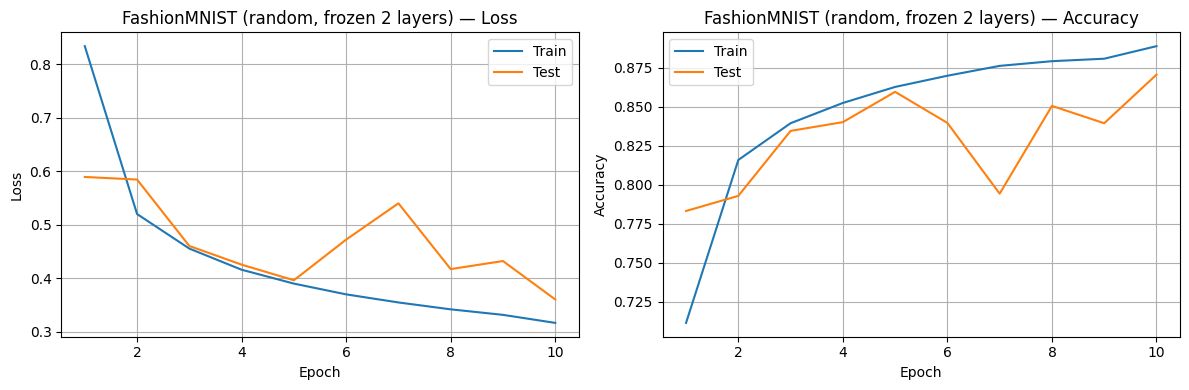

In [10]:
model3 = MultiHeadCNN().to(device)
model3.add_head2()
model3.head2 = model3.head2.to(device)

model3.freeze_initial_layers(n_layers=2)

trainable = sum(p.numel() for p in model3.parameters() if p.requires_grad)
frozen = sum(p.numel() for p in model3.parameters() if not p.requires_grad)
print(f"Обучаемых: {trainable:,}, замороженных: {frozen:,}")

optimizer3 = optim.Adam(filter(lambda p: p.requires_grad, model3.parameters()), lr=1e-3)

history_random_frozen = train_model(
    model3, fmnist_train_loader, fmnist_test_loader,
    criterion, optimizer3, epochs=10, head='head2',
    label='FashionMNIST (random, frozen 2 layers)'
)
all_histories['FashionMNIST (random, frozen 2 layers)'] = history_random_frozen
plot_curves(history_random_frozen, 'FashionMNIST (random, frozen 2 layers)')

## 9. Всё и вся

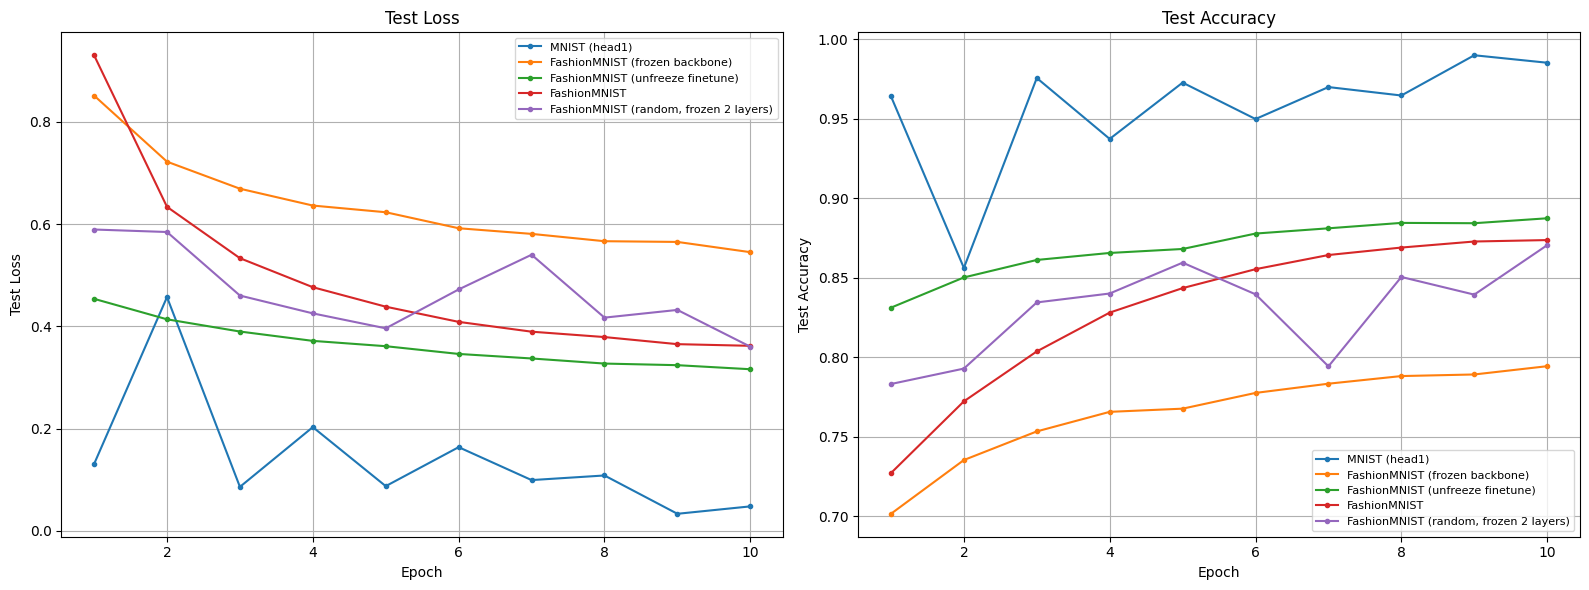

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for name, hist in all_histories.items():
    epochs = range(1, len(hist['test_loss']) + 1)
    axes[0].plot(epochs, hist['test_loss'], label=name, marker='o', markersize=3)
    axes[1].plot(epochs, hist['test_acc'], label=name, marker='o', markersize=3)

axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Test Loss')
axes[0].set_title('Test Loss')
axes[0].legend(fontsize=8)
axes[0].grid(True)

axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Test Accuracy')
axes[1].set_title('Test Accuracy')
axes[1].legend(fontsize=8)
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 10. Путаемся

Для лучшей модели на FashionMNIST строим матрицу 10×10.


In [12]:
best_name = max(
    [(k, v) for k, v in all_histories.items() if 'Fashion' in k],
    key=lambda x: max(x[1]['test_acc'])
)
print(f"Лучшая модель для FashionMNIST: {best_name[0]} "
      f"(test acc = {max(best_name[1]['test_acc']):.4f})")

best_models = {
    'FashionMNIST (frozen backbone)': model,
    'FashionMNIST (unfreeze finetune)': model,
    'FashionMNIST (from save, unfrozen)': model2,
    'FashionMNIST (random, frozen 2 layers)': model3,
}
best_model = best_models[best_name[0]]

Лучшая модель для FashionMNIST: FashionMNIST (unfreeze finetune) (test acc = 0.8874)


In [13]:
best_model.eval()
all_probs = []
all_labels = []
all_images = []

with torch.no_grad():
    for images, labels in fmnist_test_loader:
        images = images.to(device)
        logits = best_model(images, head='head2')
        probs = torch.softmax(logits, dim=1)
        all_probs.append(probs.cpu())
        all_labels.append(labels)
        all_images.append(images.cpu())

all_probs = torch.cat(all_probs, dim=0)
all_labels = torch.cat(all_labels, dim=0)
all_images = torch.cat(all_images, dim=0)

print(f"Всего тестовых изображений: {len(all_labels)}")

fmnist_classes = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
                  'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

Всего тестовых изображений: 10000


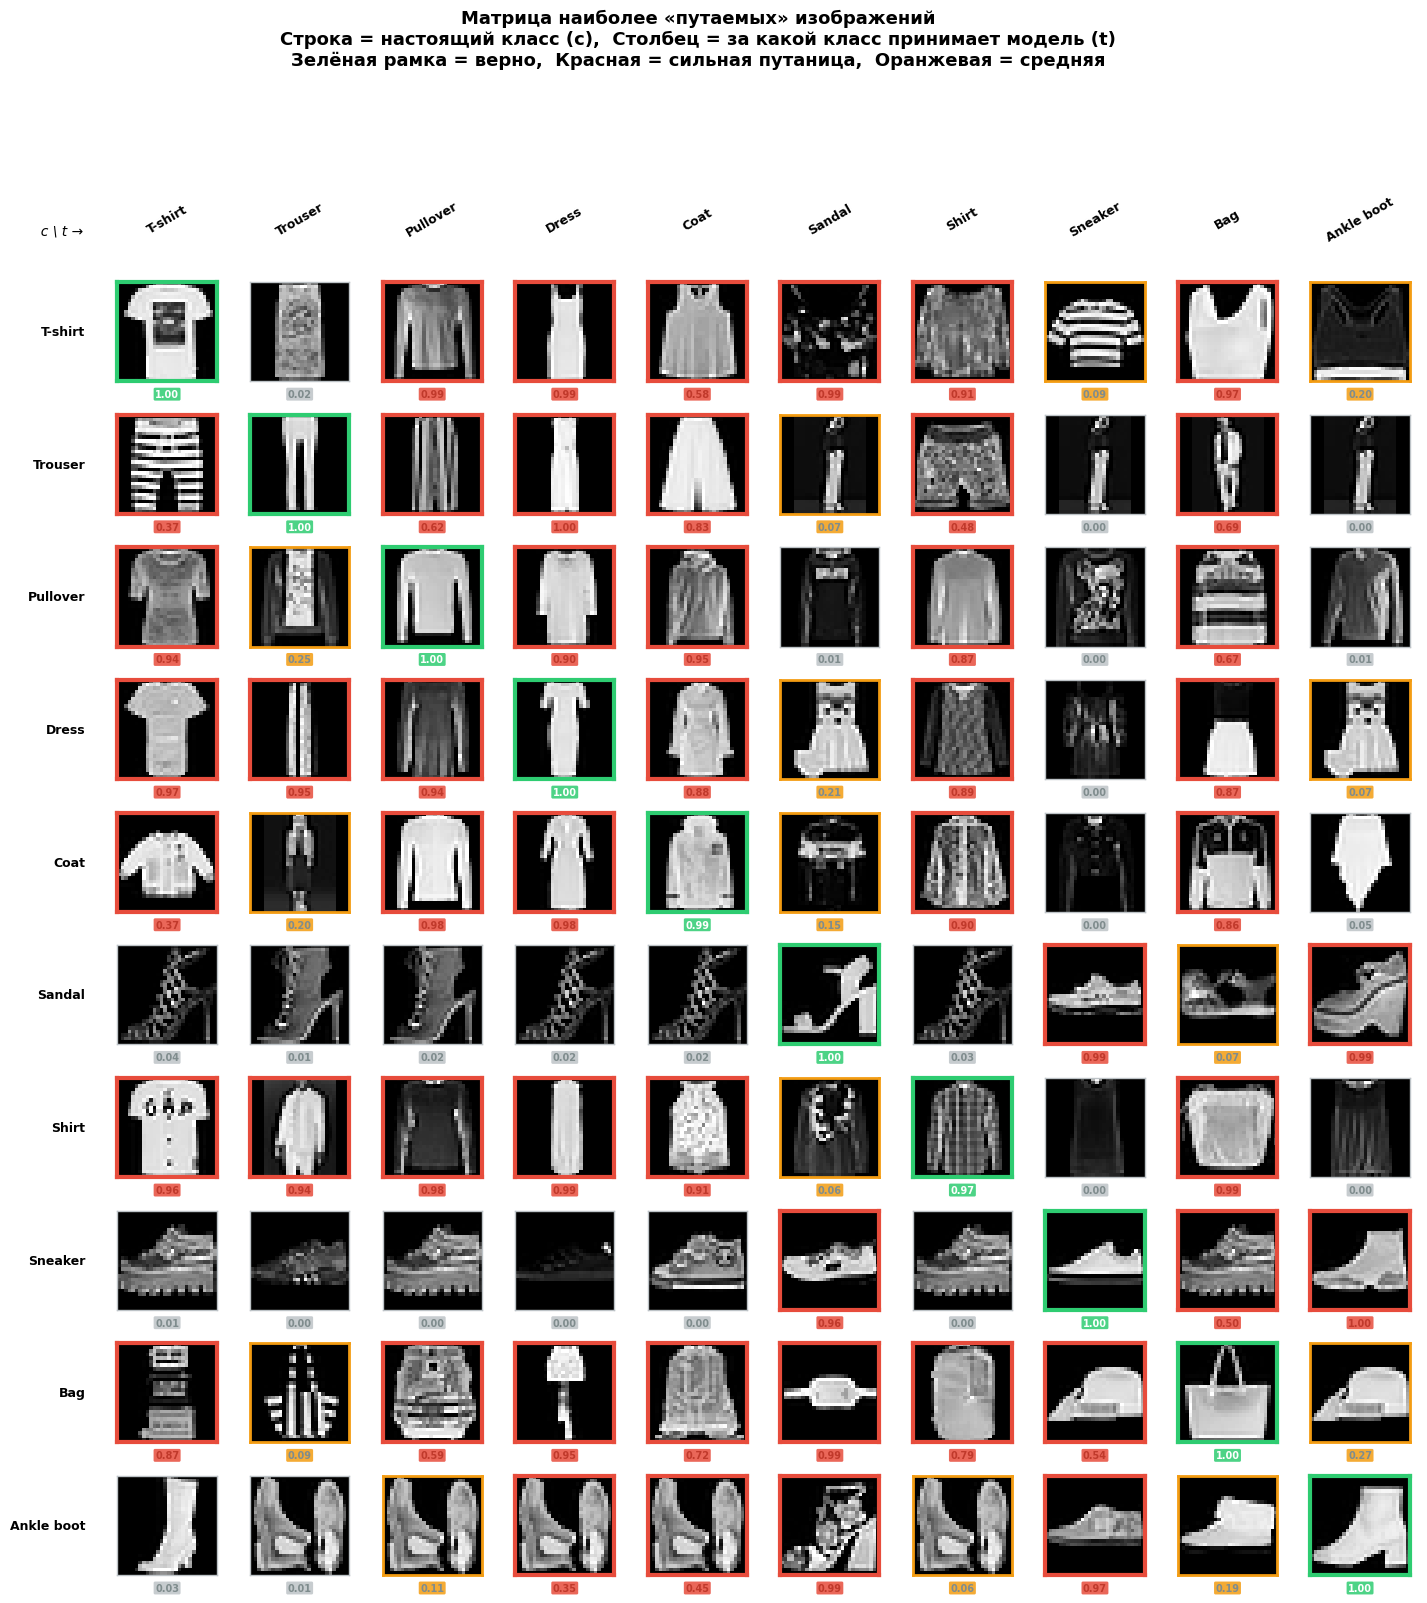

In [14]:
num_classes = 10

fig, axes = plt.subplots(num_classes + 1, num_classes + 1, figsize=(18, 18),
                         gridspec_kw={'width_ratios': [0.6] + [1]*num_classes,
                                      'height_ratios': [0.6] + [1]*num_classes})

# Заголовок
fig.suptitle('Матрица наиболее «путаемых» изображений\n'
             'Строка = настоящий класс (c),  Столбец = за какой класс принимает модель (t)\n'
             'Зелёная рамка = верно,  Красная = сильная путаница,  Оранжевая = средняя',
             fontsize=13, fontweight='bold', y=0.98)

# Верхний левый угол
axes[0][0].axis('off')
axes[0][0].text(0.5, 0.3, '  c \\ t →', fontsize=10, ha='center', va='center',
                fontstyle='italic')

# Заголовки столбцов
for t in range(num_classes):
    ax = axes[0][t + 1]
    ax.axis('off')
    ax.text(0.5, 0.5, fmnist_classes[t], fontsize=9, fontweight='bold',
            ha='center', va='center', rotation=30)

# Строки
for c in range(num_classes):
    ax_label = axes[c + 1][0]
    ax_label.axis('off')
    ax_label.text(0.9, 0.5, fmnist_classes[c], fontsize=9, fontweight='bold',
                  ha='right', va='center')

    mask_c = (all_labels == c)
    probs_c = all_probs[mask_c]
    images_c = all_images[mask_c]

    for t in range(num_classes):
        ax = axes[c + 1][t + 1]

        prob_t = probs_c[:, t]
        best_idx = prob_t.argmax().item()
        img = images_c[best_idx].squeeze().numpy() * 0.5 + 0.5
        p_val = prob_t[best_idx].item()

        ax.imshow(img, cmap='gray', vmin=0, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])

        # Цветная рамка
        if c == t:
            color = '#2ecc71'
            lw = 3
        elif p_val > 0.3:
            color = '#e74c3c'
            lw = 3
        elif p_val > 0.05:
            color = '#f39c12'
            lw = 2
        else:
            color = '#bdc3c7'
            lw = 1

        for spine in ax.spines.values():
            spine.set_edgecolor(color)
            spine.set_linewidth(lw)

        # Подпись P(t) внизу картинки
        ax.text(0.5, -0.08, f'{p_val:.2f}', fontsize=7, ha='center', va='top',
                transform=ax.transAxes,
                color='white' if c == t else ('#c0392b' if p_val > 0.3 else '#7f8c8d'),
                fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.15',
                          facecolor=color, alpha=0.85, edgecolor='none'))

plt.subplots_adjust(wspace=0.15, hspace=0.35)
plt.show()